In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [3]:
automobile_dataset = pd.read_csv('automobile_dataset5.csv')
automobile_dataset.head()

,Unnamed: 0,price,highway-mpg,city-mpg,peak-rpm,horsepower,compression-ratio,stroke,bore,fuel-system,...,engine-location,drive-wheels,body-style,num-of-doors,aspiration,fuel-type,make,normalized-losses,symboling,loss_missing
0,0,13495.0,27,21,5000.0,111.0,9.0,2.68,3.47,mpfi,...,front,rwd,convertible,2.0,std,gas,alfa-romero,NaN,3,True
1,1,16500.0,27,21,5000.0,111.0,9.0,2.68,3.47,mpfi,...,front,rwd,convertible,2.0,std,gas,alfa-romero,NaN,3,True
2,2,16500.0,26,19,5000.0,154.0,9.0,3.47,2.68,mpfi,...,front,rwd,hatchback,2.0,std,gas,alfa-romero,NaN,1,True
3,3,13950.0,30,24,5500.0,102.0,10.0,3.40,3.19,mpfi,...,front,fwd,sedan,4.0,std,gas,audi,164.0,2,False
4,4,17450.0,22,18,5500.0,115.0,8.0,3.40,3.19,mpfi,...,front,4wd,sedan,4.0,std,gas,audi,164.0,2,False


In [7]:
automobile_dataset[automobile_dataset['length'].isna()]

,price,highway-mpg,city-mpg,peak-rpm,horsepower,compression-ratio,stroke,bore,fuel-system,engine-size,...,wheel-base,engine-location,drive-wheels,body-style,num-of-doors,aspiration,fuel-type,make,normalized-losses,symboling


In [73]:
automobile_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 27 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   price              205 non-null    float64
 1   highway-mpg        205 non-null    int64  
 2   city-mpg           205 non-null    int64  
 3   peak-rpm           205 non-null    float64
 4   horsepower         205 non-null    float64
 5   compression-ratio  205 non-null    float64
 6   stroke             205 non-null    float64
 7   bore               205 non-null    float64
 8   fuel-system        205 non-null    str    
 9   engine-size        205 non-null    int64  
 10  num-of-cylinders   205 non-null    int64  
 11  engine-type        205 non-null    str    
 12  curb-weight        205 non-null    int64  
 13  height             205 non-null    float64
 14  width              205 non-null    float64
 15  length             205 non-null    float64
 16  wheel-base         205 non-null    fl

In [57]:
automobile_dataset['stroke'].describe()

count    201.000000
mean       3.255423
std        0.316717
min        2.070000
25%        3.110000
50%        3.290000
75%        3.410000
max        4.170000
Name: stroke, dtype: float64

In [36]:
automobile_dataset['stroke'] = automobile_dataset['stroke'].fillna(automobile_dataset['stroke'].mean())

In [51]:
numeric_df = automobile_dataset.select_dtypes(['float64','int64'])
corr_matrix = numeric_df.corr()
corr_matrix[corr_matrix>=0.6]

,Unnamed: 0,price,highway-mpg,city-mpg,peak-rpm,horsepower,compression-ratio,stroke,bore,engine-size,num-of-cylinders,curb-weight,height,width,length,wheel-base,num-of-doors,normalized-losses,symboling
Unnamed: 0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,NaN,1.000000,NaN,NaN,NaN,0.794037,NaN,NaN,NaN,0.874860,0.710563,0.835509,NaN,0.753868,0.689019,NaN,NaN,NaN,NaN
highway-mpg,NaN,NaN,1.000000,0.971337,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city-mpg,NaN,NaN,0.971337,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
peak-rpm,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
horsepower,NaN,0.794037,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,0.810793,0.690829,0.750864,NaN,0.642458,NaN,NaN,NaN,NaN,NaN
compression-ratio,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stroke,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bore,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,0.649370,NaN,NaN,0.607714,NaN,NaN,NaN,NaN
engine-size,NaN,0.874860,NaN,NaN,NaN,0.810793,NaN,NaN,NaN,1.000000,0.846031,0.850594,NaN,0.735433,0.683360,NaN,NaN,NaN,NaN


In [13]:
train_bore = automobile_dataset[automobile_dataset['bore'].notnull()]
train_bore

,price,highway-mpg,city-mpg,peak-rpm,horsepower,compression-ratio,stroke,bore,fuel-system,engine-size,...,wheel-base,engine-location,drive-wheels,body-style,num-of-doors,aspiration,fuel-type,make,normalized-losses,symboling
0,13495.0,27,21,5000.0,111.0,9.0,2.68,3.47,mpfi,130,...,88.6,front,rwd,convertible,2.0,std,gas,alfa-romero,NaN,3
1,16500.0,27,21,5000.0,111.0,9.0,2.68,3.47,mpfi,130,...,88.6,front,rwd,convertible,2.0,std,gas,alfa-romero,NaN,3
2,16500.0,26,19,5000.0,154.0,9.0,3.47,2.68,mpfi,152,...,94.5,front,rwd,hatchback,2.0,std,gas,alfa-romero,NaN,1
3,13950.0,30,24,5500.0,102.0,10.0,3.40,3.19,mpfi,109,...,99.8,front,fwd,sedan,4.0,std,gas,audi,164.0,2
4,17450.0,22,18,5500.0,115.0,8.0,3.40,3.19,mpfi,136,...,99.4,front,4wd,sedan,4.0,std,gas,audi,164.0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,16845.0,28,23,5400.0,114.0,9.5,3.15,3.78,mpfi,141,...,109.1,front,rwd,sedan,4.0,std,gas,volvo,95.0,-1
201,19045.0,25,19,5300.0,160.0,8.7,3.15,3.78,mpfi,141,...,109.1,front,rwd,sedan,4.0,turbo,gas,volvo,95.0,-1
202,21485.0,23,18,5500.0,134.0,8.8,2.87,3.58,mpfi,173,...,109.1,front,rwd,sedan,4.0,std,gas,volvo,95.0,-1
203,22470.0,27,26,4800.0,106.0,23.0,3.40,3.01,idi,145,...,109.1,front,rwd,sedan,4.0,turbo,diesel,volvo,95.0,-1


In [18]:
missing_bore = automobile_dataset[automobile_dataset['bore'].isna()]
missing_bore

,price,highway-mpg,city-mpg,peak-rpm,horsepower,compression-ratio,stroke,bore,fuel-system,engine-size,...,wheel-base,engine-location,drive-wheels,body-style,num-of-doors,aspiration,fuel-type,make,normalized-losses,symboling
55,10945.0,23,17,6000.0,101.0,9.4,NaN,NaN,4bbl,70,...,95.3,front,rwd,hatchback,2.0,std,gas,mazda,150.0,3
56,11845.0,23,17,6000.0,101.0,9.4,NaN,NaN,4bbl,70,...,95.3,front,rwd,hatchback,2.0,std,gas,mazda,150.0,3
57,13645.0,23,17,6000.0,101.0,9.4,NaN,NaN,4bbl,70,...,95.3,front,rwd,hatchback,2.0,std,gas,mazda,150.0,3
58,15645.0,23,16,6000.0,135.0,9.4,NaN,NaN,mpfi,80,...,95.3,front,rwd,hatchback,2.0,std,gas,mazda,150.0,3


In [25]:
y = train_bore['bore']
x = train_bore[['curb-weight']]
model = LinearRegression()
model.fit(x, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['curb-weight']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.465
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [32]:
predicted = model.predict(missing_bore[['curb-weight']])

In [34]:
automobile_dataset.loc[automobile_dataset['bore'].isna(),'bore'] = predicted

In [40]:
norm_null = automobile_dataset[automobile_dataset['normalized-losses'].isna()]
norm_not_null = automobile_dataset[automobile_dataset['normalized-losses'].notnull()]

In [42]:
norm_null.describe()

,price,highway-mpg,city-mpg,peak-rpm,horsepower,compression-ratio,stroke,bore,engine-size,num-of-cylinders,curb-weight,height,width,length,wheel-base,num-of-doors,normalized-losses,symboling
count,37.00000,41.000000,41.000000,39.000000,39.000000,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000,40.000000,0.0,41.000000
mean,20922.27027,26.365854,21.024390,5073.076923,138.102564,10.204878,3.326098,3.451951,162.707317,5.170732,2944.731707,53.526829,67.143902,181.292683,101.126829,2.950000,NaN,1.000000
std,11108.06792,6.654908,6.278884,481.478829,54.428995,4.526088,0.388644,0.266038,57.549650,1.701506,518.503425,2.830638,2.538213,13.334005,8.420511,1.011473,NaN,1.322876
min,6785.00000,16.000000,13.000000,4150.000000,64.000000,7.000000,2.190000,2.680000,90.000000,4.000000,1874.000000,47.800000,61.800000,155.900000,88.600000,2.000000,NaN,-1.000000
25%,12764.00000,24.000000,17.000000,4775.000000,95.000000,8.000000,3.110000,3.270000,130.000000,4.000000,2579.000000,51.600000,65.500000,172.600000,95.900000,2.000000,NaN,0.000000
50%,16500.00000,25.000000,19.000000,5000.000000,145.000000,8.700000,3.390000,3.460000,152.000000,4.000000,2833.000000,53.700000,66.600000,178.200000,99.800000,2.000000,NaN,0.000000
75%,32528.00000,29.000000,24.000000,5450.000000,179.000000,9.500000,3.470000,3.620000,194.000000,6.000000,3285.000000,55.600000,68.400000,192.700000,104.900000,4.000000,NaN,2.000000
max,45400.00000,43.000000,38.000000,5900.000000,288.000000,23.000000,4.170000,3.940000,326.000000,12.000000,4066.000000,58.700000,72.300000,208.100000,120.900000,4.000000,NaN,3.000000


In [43]:
norm_not_null.describe()

,price,highway-mpg,city-mpg,peak-rpm,horsepower,compression-ratio,stroke,bore,engine-size,num-of-cylinders,curb-weight,height,width,length,wheel-base,num-of-doors,normalized-losses,symboling
count,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,164.000000,163.000000,164.000000,164.000000
mean,11466.518293,31.847561,26.268293,5137.804878,96.207317,10.126951,3.237754,3.297988,117.957317,4.182927,2458.274390,53.774390,65.598780,172.238415,98.164024,3.165644,122.000000,0.792683
std,5803.490319,6.514349,6.193305,479.459113,30.408563,3.836306,0.290591,0.264077,30.896294,0.745178,475.087068,2.343942,1.923028,11.417833,5.120198,0.989225,35.442168,1.225874
min,5118.000000,18.000000,15.000000,4150.000000,48.000000,7.000000,2.070000,2.540000,61.000000,2.000000,1488.000000,49.400000,60.300000,141.100000,86.600000,2.000000,65.000000,-2.000000
25%,7446.000000,28.000000,22.000000,4800.000000,69.000000,8.700000,3.110000,3.050000,97.000000,4.000000,2090.750000,52.000000,64.000000,165.675000,94.500000,2.000000,94.000000,0.000000
50%,9268.500000,32.000000,26.000000,5200.000000,91.000000,9.000000,3.270000,3.270000,109.000000,4.000000,2367.500000,54.100000,65.400000,172.000000,96.550000,4.000000,115.000000,1.000000
75%,14559.250000,37.000000,31.000000,5500.000000,114.000000,9.400000,3.410000,3.540000,131.750000,4.000000,2785.500000,55.500000,66.500000,177.800000,100.400000,4.000000,150.000000,2.000000
max,35056.000000,54.000000,49.000000,6600.000000,200.000000,23.000000,4.170000,3.940000,258.000000,8.000000,4066.000000,59.800000,71.700000,202.600000,115.600000,4.000000,256.000000,3.000000


In [45]:
per_mat = (norm_null.describe()-norm_not_null.describe())/norm_not_null.describe()
per_mat[per_mat>=0.6]

,price,highway-mpg,city-mpg,peak-rpm,horsepower,compression-ratio,stroke,bore,engine-size,num-of-cylinders,curb-weight,height,width,length,wheel-base,num-of-doors,normalized-losses,symboling
count,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,0.824640,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.914032,NaN,NaN,NaN,0.789923,NaN,NaN,NaN,0.862672,1.283356,NaN,NaN,NaN,NaN,0.644568,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.714209,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.780223,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.234181,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [40]:
automobile_dataset['loss_missing'] = automobile_dataset['normalized-losses'].isna()
automobile_dataset = automobile_dataset.drop('Unnamed: 0', axis=1)

In [32]:
automobile_dataset[automobile_dataset['body-style'].isin(['sedan']) & automobile_dataset['num-of-doors'].isin([2])]

,price,highway-mpg,city-mpg,peak-rpm,horsepower,compression-ratio,stroke,bore,fuel-system,engine-size,...,engine-location,drive-wheels,body-style,num-of-doors,aspiration,fuel-type,make,normalized-losses,symboling,loss_missing
5,15250.0,25,19,5500.0,110.0,8.5,3.40,3.19,mpfi,136,...,front,fwd,sedan,2.0,std,gas,audi,NaN,2,True
10,16430.0,29,23,5800.0,101.0,8.8,2.80,3.50,mpfi,108,...,front,rwd,sedan,2.0,std,gas,bmw,192.0,2,False
12,20970.0,28,21,4250.0,121.0,9.0,3.19,3.31,mpfi,164,...,front,rwd,sedan,2.0,std,gas,bmw,188.0,0,False
16,41315.0,22,16,5400.0,182.0,8.0,3.39,3.62,mpfi,209,...,front,rwd,sedan,2.0,std,gas,bmw,NaN,0,True
42,10345.0,31,25,5500.0,100.0,9.1,3.58,3.15,2bbl,110,...,front,fwd,sedan,2.0,std,gas,honda,107.0,1,False
44,NaN,43,38,5400.0,70.0,9.6,3.11,3.03,2bbl,90,...,front,fwd,sedan,2.0,std,gas,isuzu,NaN,1,True
49,36000.0,17,13,5000.0,262.0,11.5,2.76,3.54,mpfi,326,...,front,rwd,sedan,2.0,std,gas,jaguar,NaN,0,True
89,5499.0,37,31,5200.0,69.0,9.4,3.29,3.15,2bbl,97,...,front,fwd,sedan,2.0,std,gas,nissan,128.0,1,False
90,7099.0,50,45,4800.0,55.0,21.9,3.47,2.99,idi,103,...,front,fwd,sedan,2.0,std,diesel,nissan,128.0,1,False
91,6649.0,37,31,5200.0,69.0,9.4,3.29,3.15,2bbl,97,...,front,fwd,sedan,2.0,std,gas,nissan,128.0,1,False


In [44]:
automobile_dataset[automobile_dataset['num-of-doors'].isna()]

,price,highway-mpg,city-mpg,peak-rpm,horsepower,compression-ratio,stroke,bore,fuel-system,engine-size,...,engine-location,drive-wheels,body-style,num-of-doors,aspiration,fuel-type,make,normalized-losses,symboling,loss_missing


In [43]:
automobile_dataset['num-of-doors'] = automobile_dataset['num-of-doors'].fillna(4)

In [57]:
automobile_dataset[automobile_dataset['horsepower'].isna()]

,price,highway-mpg,city-mpg,peak-rpm,horsepower,compression-ratio,stroke,bore,fuel-system,engine-size,...,engine-location,drive-wheels,body-style,num-of-doors,aspiration,fuel-type,make,normalized-losses,symboling,loss_missing


In [51]:
mis_hp = automobile_dataset[automobile_dataset['horsepower'].isna()]
train_hp = automobile_dataset[automobile_dataset['horsepower'].notnull()]
x = train_hp[['engine-size']]
y = train_hp['horsepower']
model = LinearRegression()
model.fit(x, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.77]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['engine-size']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6.641
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [55]:
predicted = model.predict(mis_hp[['engine-size']])
predicted

array([108.21351354, 108.21351354])

In [56]:
automobile_dataset.loc[automobile_dataset['horsepower'].isna(), 'horsepower'] = predicted 

In [61]:
automobile_dataset['peak-rpm'].describe()

count     203.000000
mean     5125.369458
std       479.334560
min      4150.000000
25%      4800.000000
50%      5200.000000
75%      5500.000000
max      6600.000000
Name: peak-rpm, dtype: float64

In [62]:
automobile_dataset['peak-rpm'].skew()

np.float64(0.07323669149378166)

In [63]:
automobile_dataset['peak-rpm'] = automobile_dataset['peak-rpm'].fillna(automobile_dataset['peak-rpm'].mean())

In [70]:
price_mis = automobile_dataset[automobile_dataset['price'].isna()]
price_train = automobile_dataset[automobile_dataset['price'].notnull()]
x = price_train[['engine-size']]
y = price_train['price']
model_price = LinearRegression()
model_price.fit(x, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[166.86]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['engine-size']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-7963
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [71]:
predicted = model_price.predict(price_mis[['engine-size']])
predicted

array([13895.32314929,  7054.06250595,  7054.06250595, 25909.24427908])

In [72]:
automobile_dataset.loc[automobile_dataset['price'].isna(), 'price'] = predicted

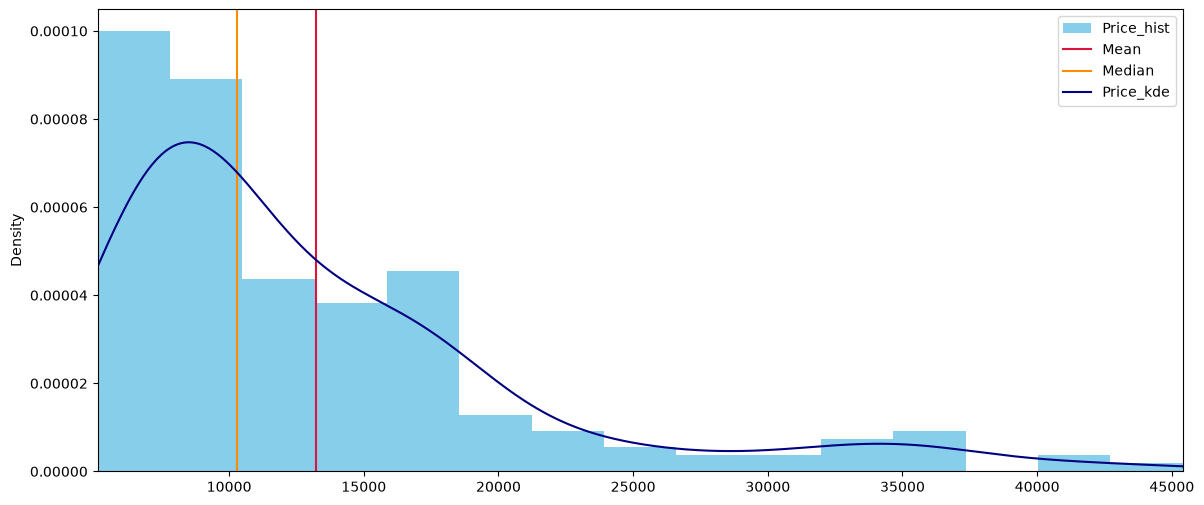

In [33]:
automobile_dataset['price'].plot(kind='hist', figsize=(14,6), bins=15,density=True, label='Price_hist', color='skyblue')
plt.axvline(automobile_dataset['price'].mean(), color='crimson', label='Mean')
plt.axvline(automobile_dataset['price'].median(), color='darkorange', label='Median')
automobile_dataset['price'].plot(kind='kde', color='navy',label='Price_kde')
plt.xlim([automobile_dataset['price'].min(),automobile_dataset['price'].max()])
plt.legend()

In [47]:
numbers_column = automobile_dataset.select_dtypes(['float64','int64']).drop('Unnamed: 0', axis=1).columns


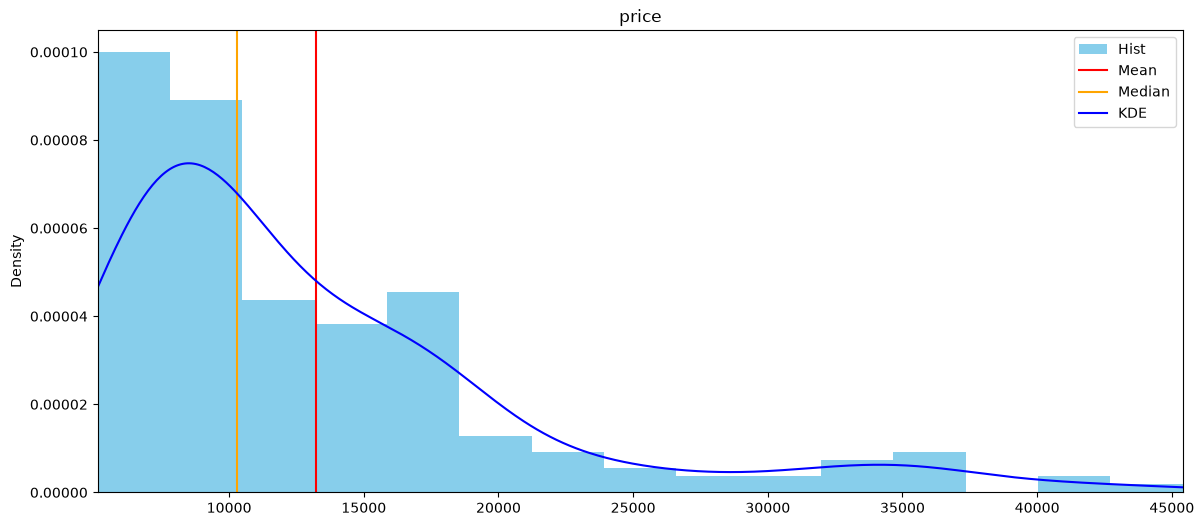

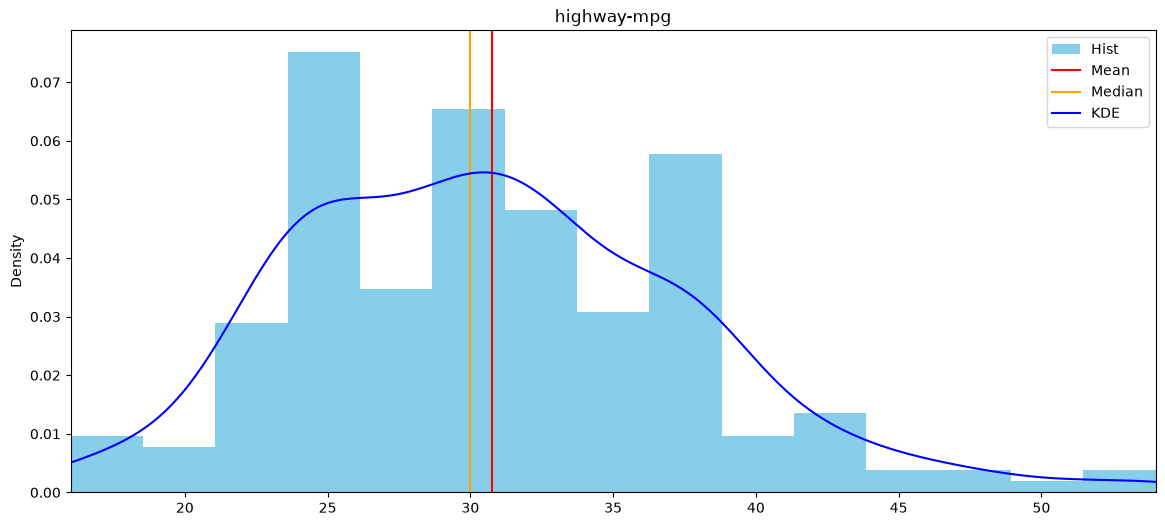

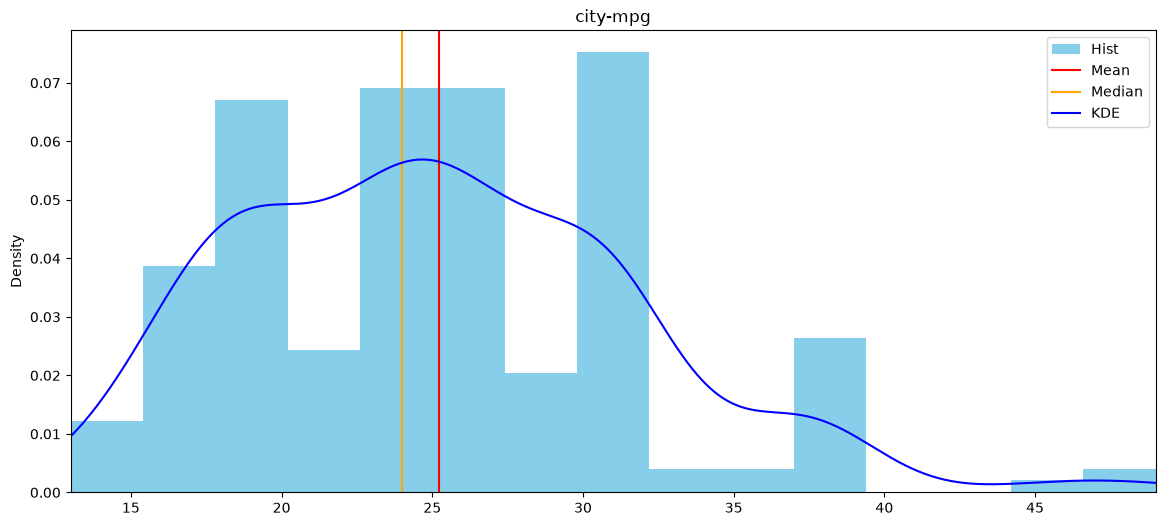

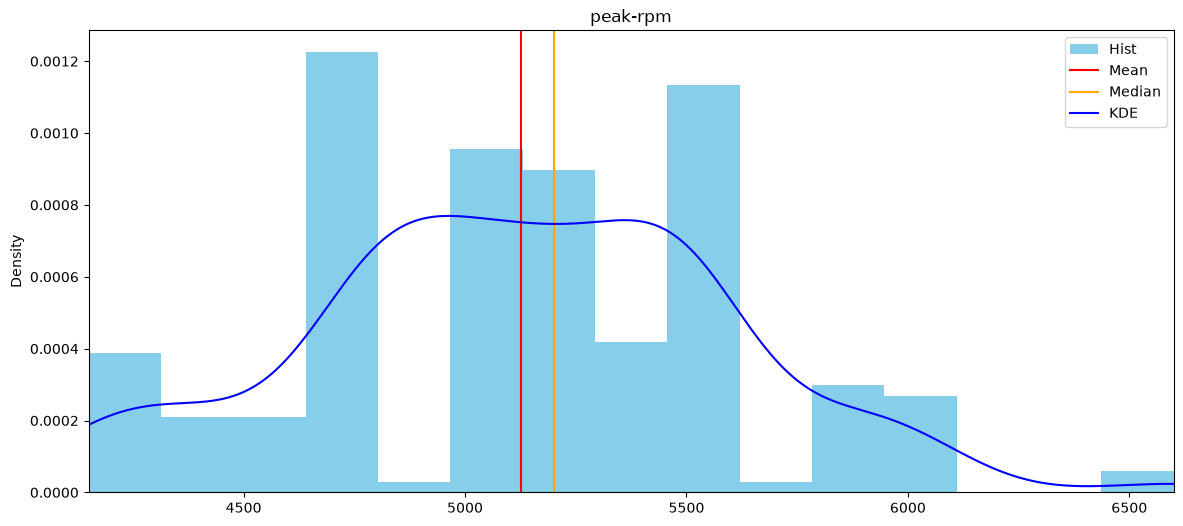

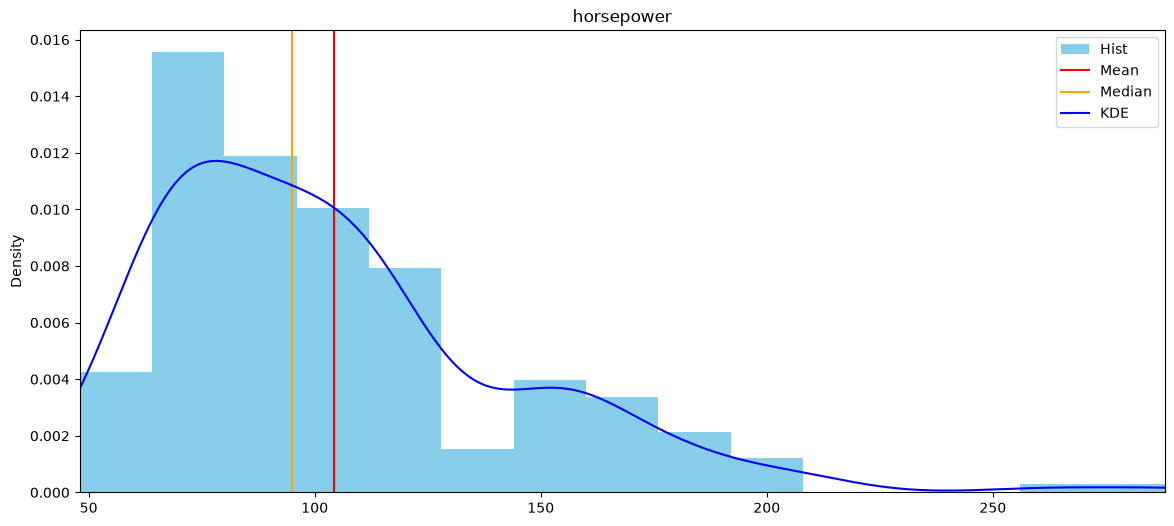

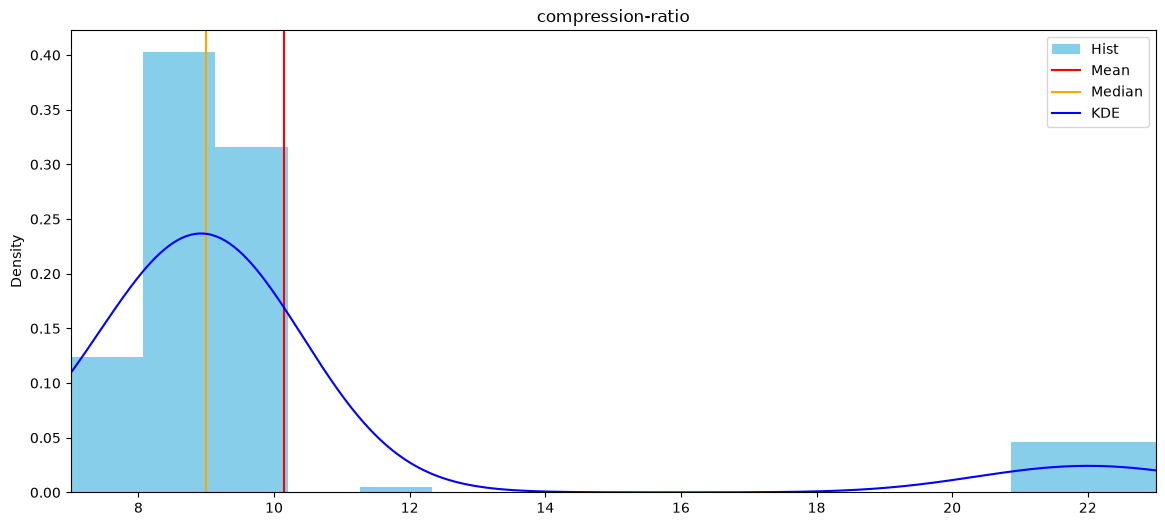

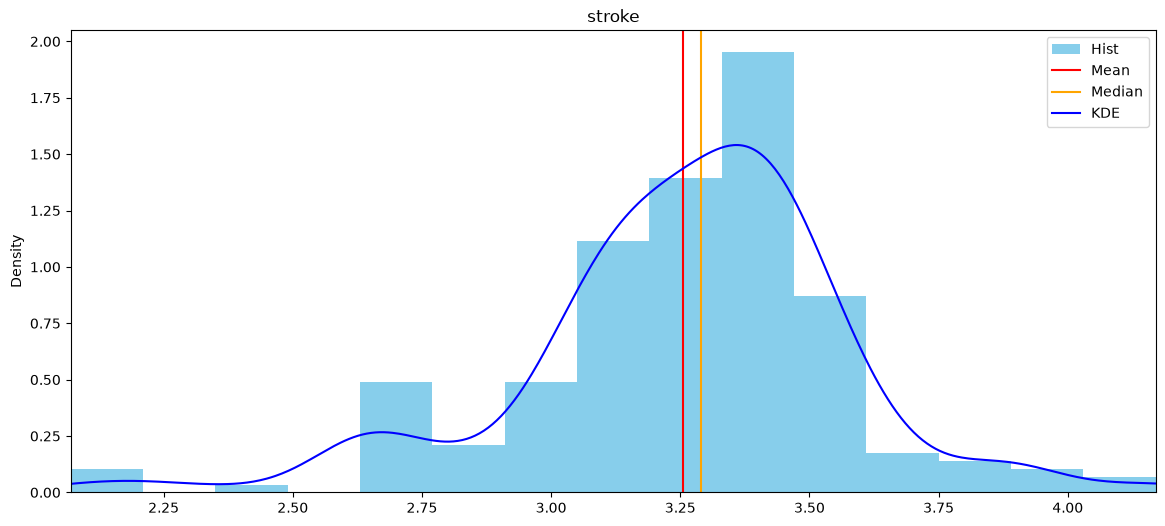

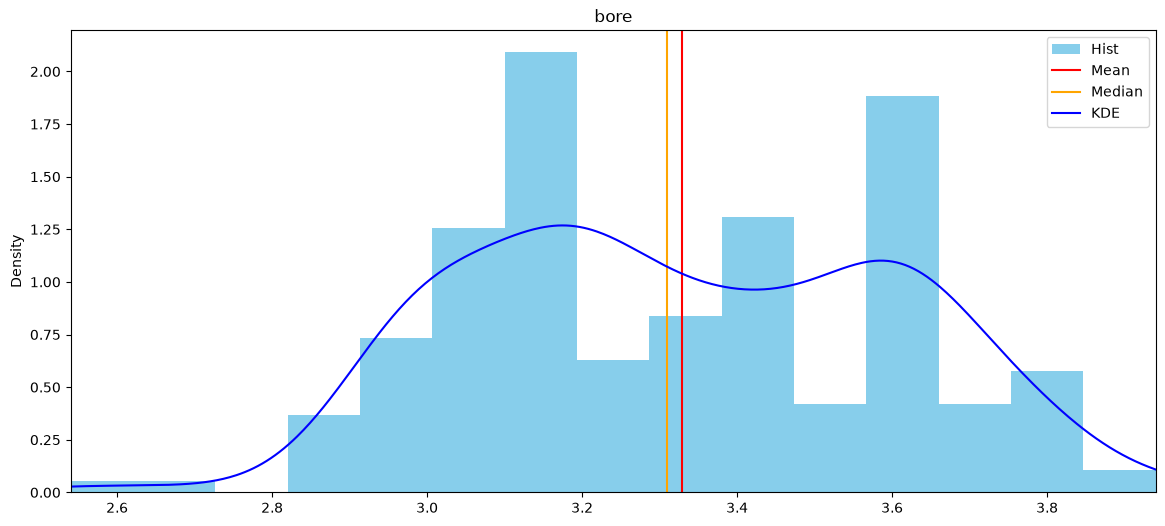

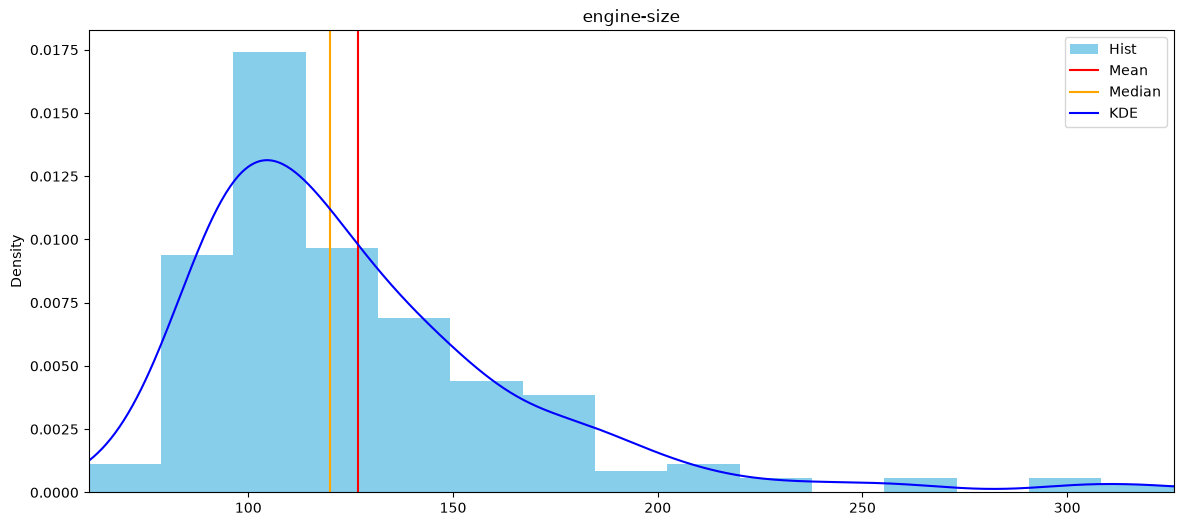

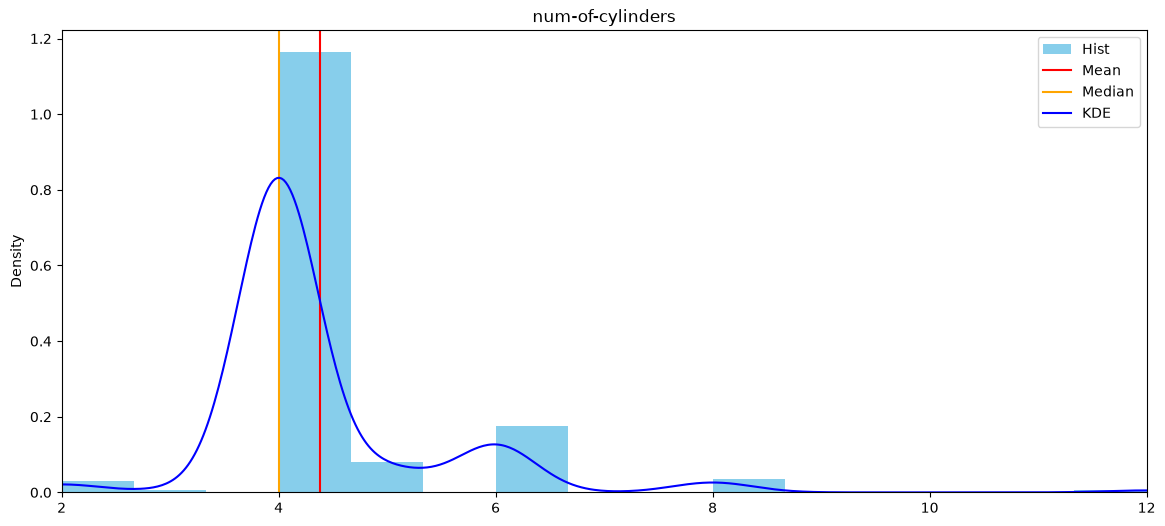

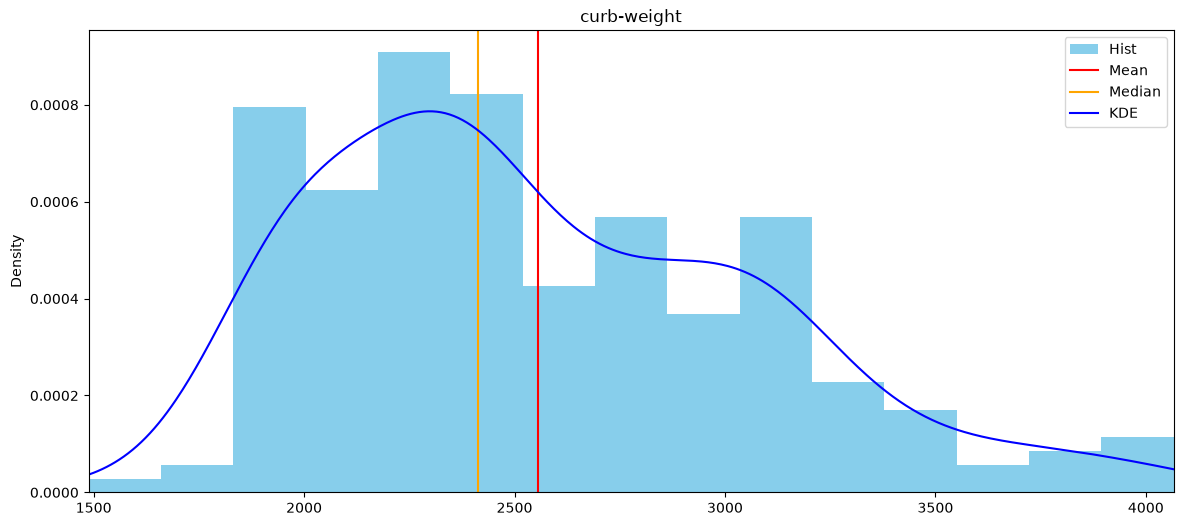

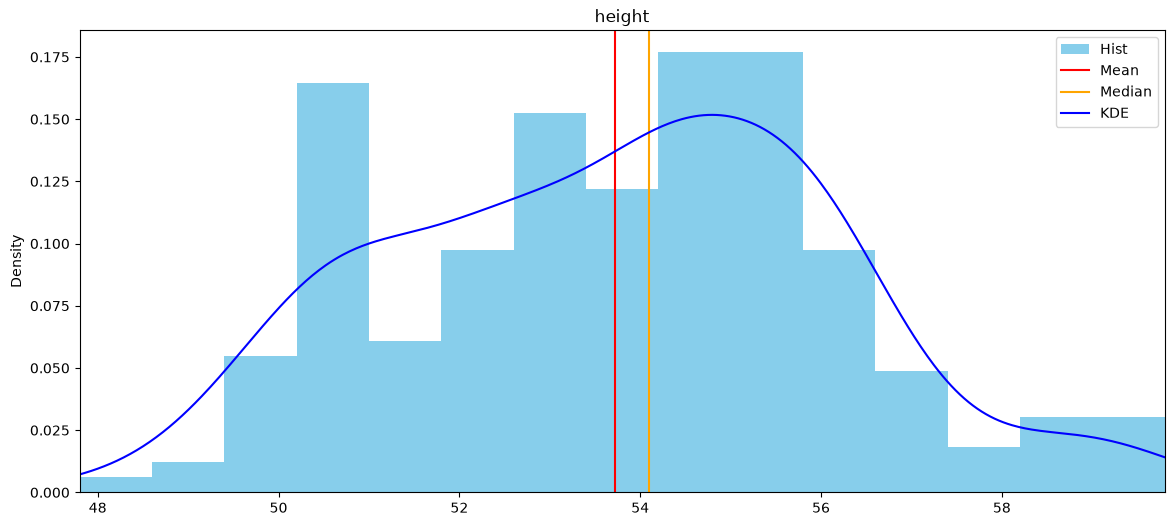

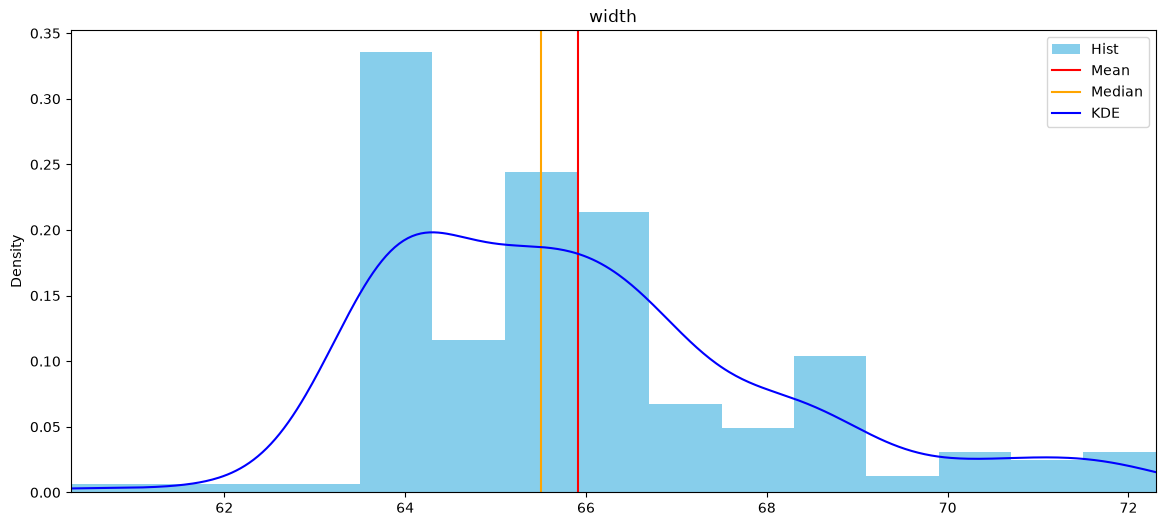

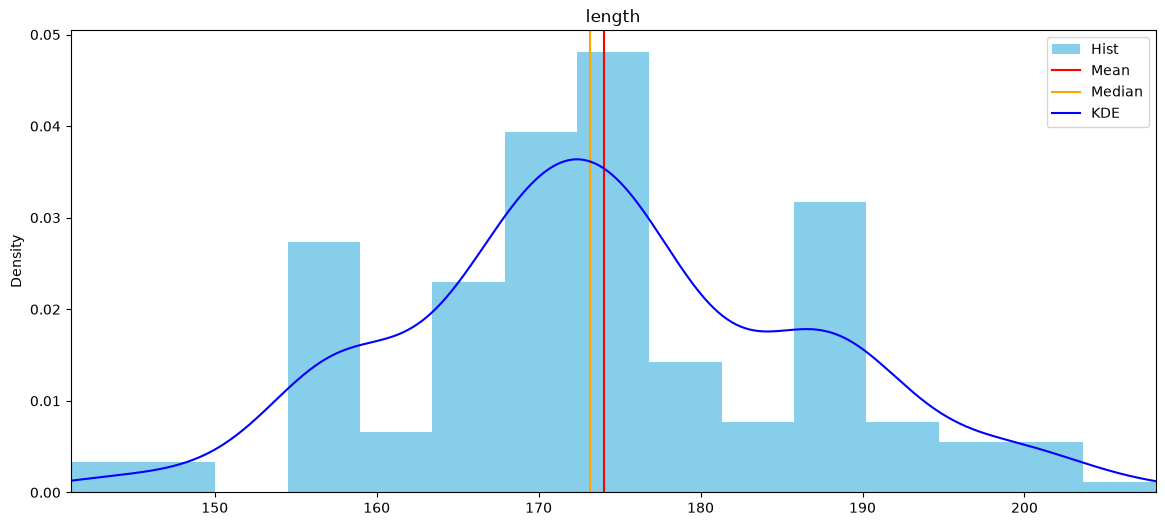

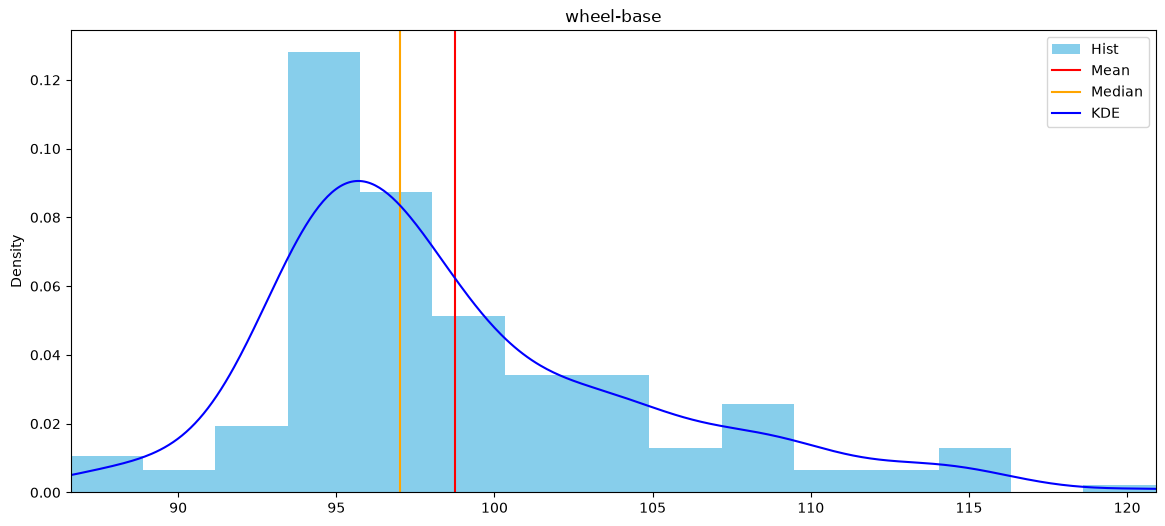

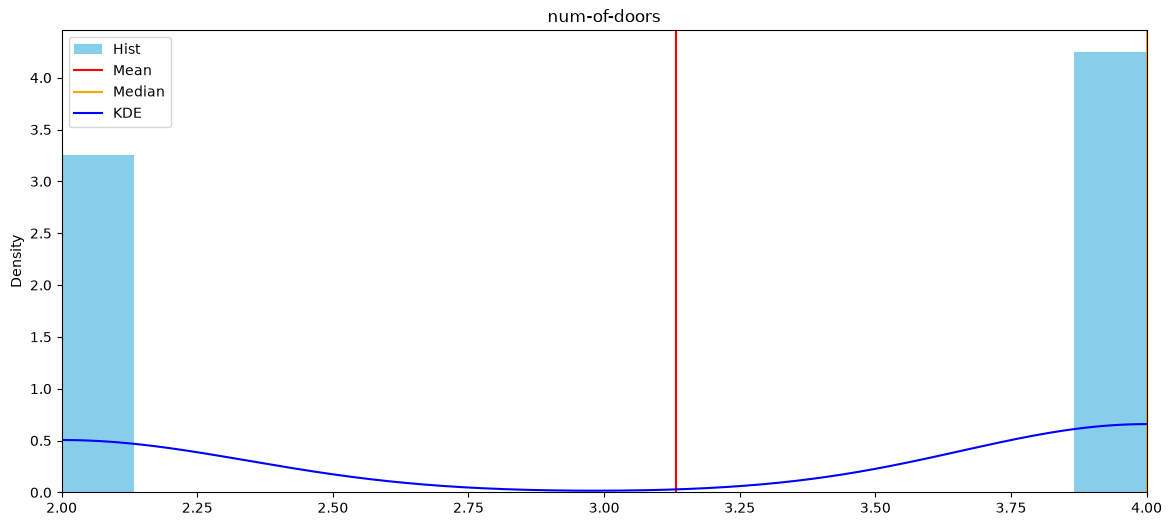

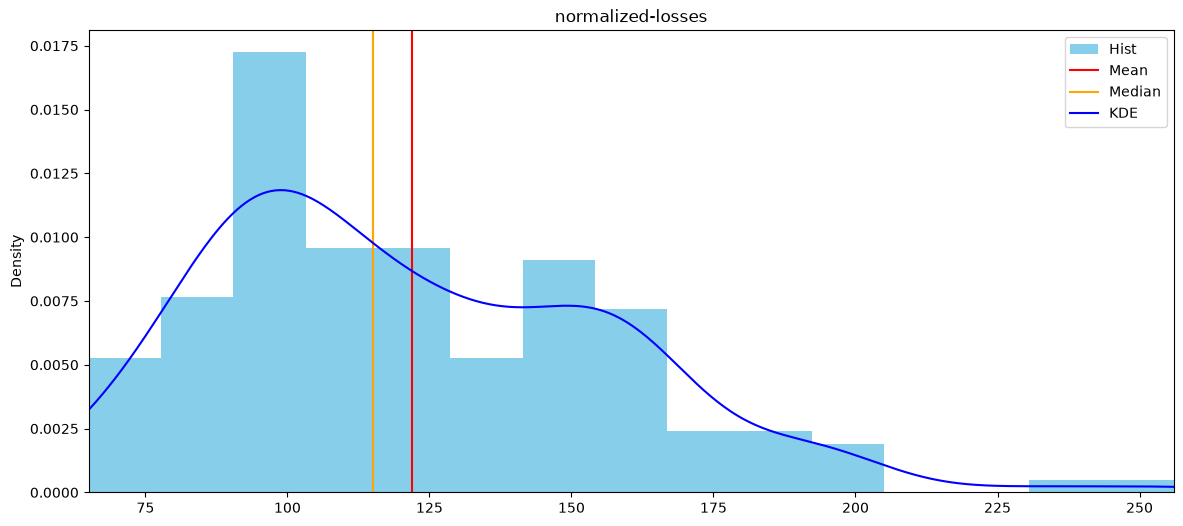

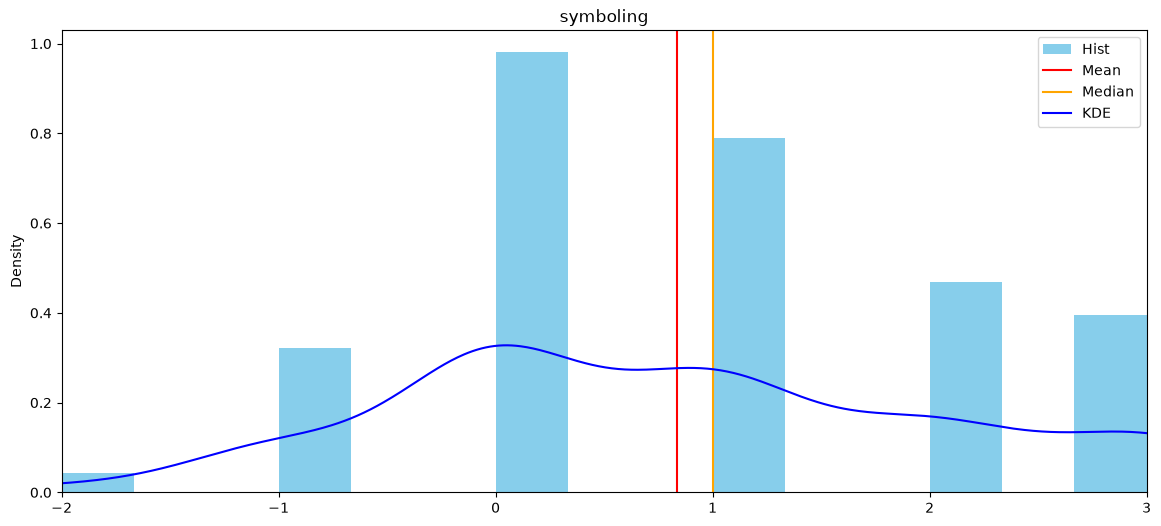

In [49]:
for column in numbers_column:
    automobile_dataset[column].plot(kind='hist', figsize=(14,6), bins=15,density=True, label='Hist', color='skyblue')
    plt.axvline(automobile_dataset[column].mean(), color='red', label='Mean')
    plt.axvline(automobile_dataset[column].median(), color='orange', label='Median')
    automobile_dataset[column].plot(kind='kde', color='blue',label='KDE')
    plt.xlim([automobile_dataset[column].min(),automobile_dataset[column].max()])
    plt.title(column)
    plt.legend()
    plt.show()

In [50]:
automobile_dataset[automobile_dataset['num-of-cylinders']==12]

,Unnamed: 0,price,highway-mpg,city-mpg,peak-rpm,horsepower,compression-ratio,stroke,bore,fuel-system,...,engine-location,drive-wheels,body-style,num-of-doors,aspiration,fuel-type,make,normalized-losses,symboling,loss_missing
49,49,36000.0,17,13,5000.0,262.0,11.5,2.76,3.54,mpfi,...,front,rwd,sedan,2.0,std,gas,jaguar,NaN,0,True


In [53]:
automobile_dataset = automobile_dataset.drop('Unnamed: 0', axis=1)
automobile_dataset.to_csv('automobile_dataset_cleaned.csv', index=False)